# PCA: Dimensionality Reduction vs. Information Loss (UML501, Project 10)

## Problem definition
MNIST images have 784 pixel features. Many of them carry little information (for example, border pixels that are almost always black). This project measures how reducing the number of features with Principal Component Analysis (PCA) affects retained variance, training time and classification performance.

### Research questions
1. **RQ1:** How many principal components are needed to keep most of the variance in MNIST?
2. **RQ2:** How do accuracy and F1 change as the number of components drops from 784 to 300, 200, 100 and 50?
3. **RQ3:** How much training and prediction time does PCA save, and is the trade-off worth it?

### Motivation
Fewer features mean faster training, less memory and sometimes less noise. In real systems (mobile apps, large datasets) this saving matters, but only if accuracy stays acceptable.

### Background
- PCA was introduced by Karl Pearson (1901) and developed by Harold Hotelling (1933).
- PCA finds new axes (principal components) along which the data varies most, and keeps only the top ones.
- It is unsupervised: it uses only the features, never the labels.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

SEED = 42
np.random.seed(SEED)
print("Setup done ✅")

Setup done ✅


In [15]:
import sys, platform, subprocess, sklearn, matplotlib

chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                      capture_output=True, text=True).stdout.strip()
print("Python:      ", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("NumPy:       ", np.__version__, "| pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
print("OS:          ", platform.platform())
print("Chip:        ", chip)

Python:       3.14.6
scikit-learn: 1.9.1
NumPy:        2.5.4 | pandas: 3.0.6 | matplotlib: 3.11.2
OS:           macOS-26.6.2-arm64-arm-64bit-Mach-O
Chip:         Apple M3


## Dataset: MNIST

| Item | Details |
|---|---|
| Name | MNIST handwritten digits (`mnist_784`) |
| Source | OpenML dataset ID 554 (openml.org/d/554), loaded with `sklearn.datasets.fetch_openml`; original: yann.lecun.com/exdb/mnist |
| Creators | Yann LeCun, Corinna Cortes, Christopher J.C. Burges (1998) |
| License | CC BY-SA 3.0 |
| Samples | 70,000 images (first 60,000 = official training set, last 10,000 = official test set) |
| Features | 784 = 28 × 28 grayscale pixels, values 0–255 |
| Target | Digit class 0–9 (10 classes) |
| Limitations | Clean, centred digits, easier than real handwriting; mostly US writers; pixel features are highly correlated, which is exactly why PCA works well here |

In [2]:
start = time.time()
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, parser="auto")
y = y.astype(int)

print(f"Loaded in {time.time() - start:.1f} seconds")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Pixel range:", X.min(), "to", X.max())

Loaded in 1.5 seconds
X shape: (70000, 784)
y shape: (70000,)
Pixel range: 0 to 255


## Exploratory Data Analysis (EDA)

### 1. Sample images
First I looked at some images to see what the data looks like.

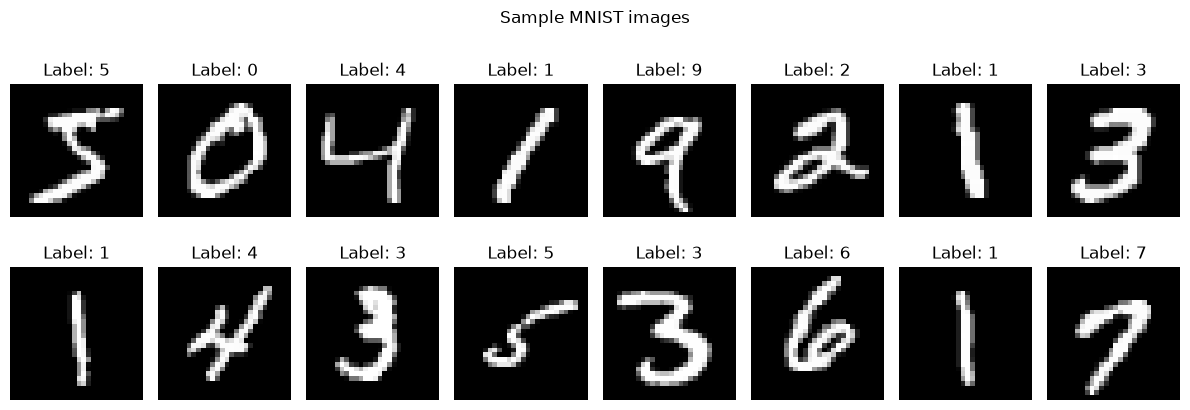

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST images")
plt.tight_layout()
plt.show()

### 2. Class balance
Next I checked how many images there are for each digit. If some digits had a lot more images than others, accuracy alone would not be a fair metric.

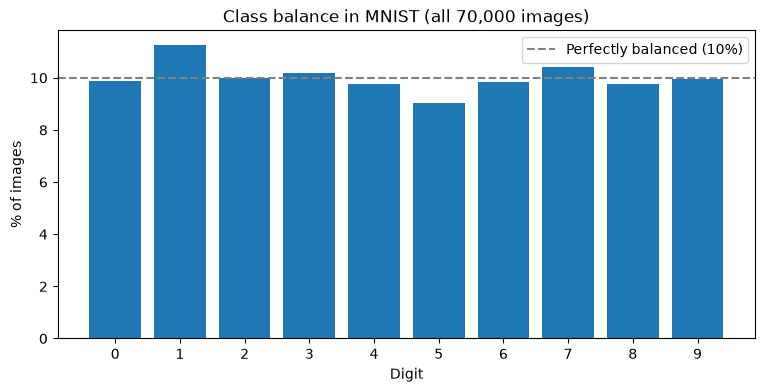

   count  percent
0   6903     9.86
1   7877    11.25
2   6990     9.99
3   7141    10.20
4   6824     9.75
5   6313     9.02
6   6876     9.82
7   7293    10.42
8   6825     9.75
9   6958     9.94


In [4]:
counts = pd.Series(y).value_counts().sort_index()
percent = counts / counts.sum() * 100

plt.figure(figsize=(9, 4))
plt.bar(counts.index, percent)
plt.axhline(10, color="gray", linestyle="--", label="Perfectly balanced (10%)")
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("% of images")
plt.title("Class balance in MNIST (all 70,000 images)")
plt.legend()
plt.show()

print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

**Finding:** Every digit is between 9.02% (digit 5) and 11.25% (digit 1) of the data, so the classes are balanced. Accuracy is a fair metric here, but I will also report macro-F1.

### 3. Which pixels actually change?
PCA works best when many features are useless or repeat the same information. So I checked how much each of the 784 pixels changes across all images. If a pixel is always black, it gives the model no information.

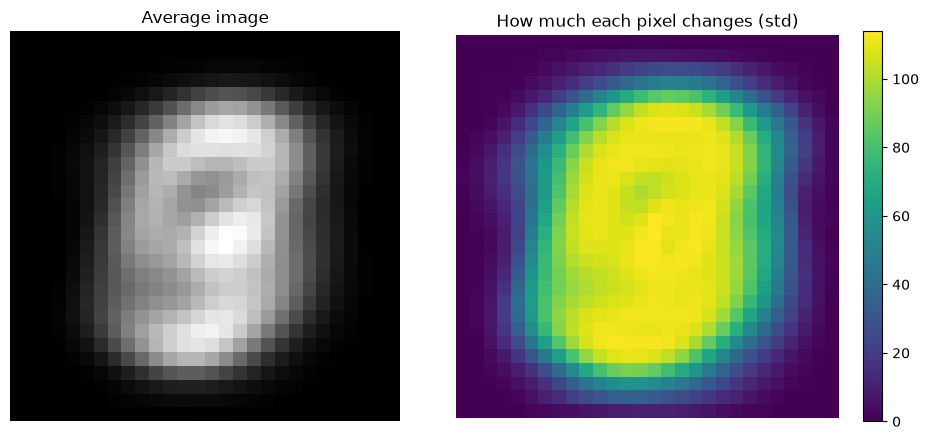

Total pixels: 784
Pixels that are always 0 in every image: 65
Pixels with very low change (std < 10): 263


In [5]:
pixel_std = X.std(axis=0)
always_zero = (X.max(axis=0) == 0).sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

axes[0].imshow(X.mean(axis=0).reshape(28, 28), cmap="gray")
axes[0].set_title("Average image")
axes[0].axis("off")

im = axes[1].imshow(pixel_std.reshape(28, 28), cmap="viridis")
axes[1].set_title("How much each pixel changes (std)")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.show()

print("Total pixels:", X.shape[1])
print("Pixels that are always 0 in every image:", always_zero)
print("Pixels with very low change (std < 10):", (pixel_std < 10).sum())

**Finding:** 65 of the 784 pixels are 0 in every single image, and 263 pixels (about one third) barely change (std < 10). These pixels are mostly on the border. They carry almost no information, so the data has many more features than it really needs. This is the main reason PCA should work well on MNIST.

## Preprocessing

**Split:** I used the official MNIST split. The first 60,000 images are the training set and the last 10,000 are the test set. From the training set I kept 10,000 images aside as a validation set, so the test set is only used once at the very end.

**Scaling:** I divided all pixels by 255, so every value is between 0 and 1. This is a fixed operation, so no information from the validation or test set leaks into training. I did not use StandardScaler, because it would blow up tiny changes in the almost-constant border pixels.

**Not needed:** no missing values, no categorical features to encode, and no imbalance handling (classes are balanced).

In [6]:
from sklearn.model_selection import train_test_split

X = X / 255.0

X_train_full, X_test = X[:60000], X[60000:]
y_train_full, y_test = y[:60000], y[60000:]

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=10000,
    random_state=SEED, stratify=y_train_full)

print("Train:     ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)
print("Pixel range now:", X_train.min(), "to", X_train.max())

Train:      (50000, 784)
Validation: (10000, 784)
Test:       (10000, 784)
Pixel range now: 0.0 to 1.0


## PCA: how much information do we keep?

I fitted PCA on the training set only (not on validation or test), so no information leaks. Then I checked the explained variance ratio, which tells how much of the total variation in the data each component keeps. Adding them up gives the cumulative explained variance.

PCA fit time: 0.1 seconds
80% variance needs 44 components (5.6% of 784)
90% variance needs 87 components (11.1% of 784)
95% variance needs 154 components (19.6% of 784)
99% variance needs 331 components (42.2% of 784)


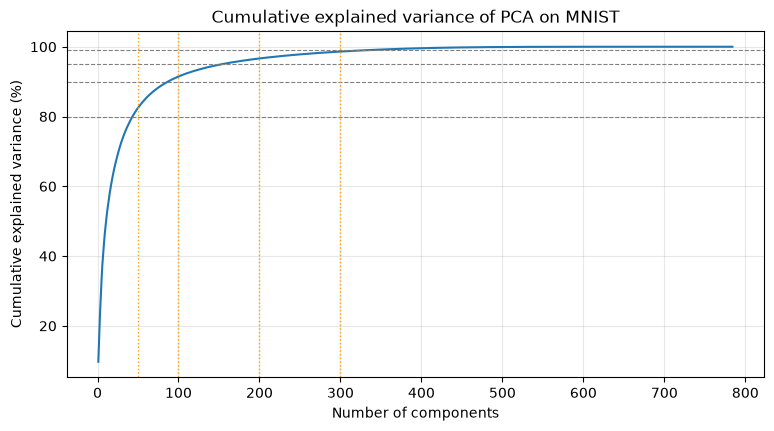

In [7]:
from sklearn.decomposition import PCA

start = time.time()
pca_full = PCA(random_state=SEED).fit(X_train)
print(f"PCA fit time: {time.time() - start:.1f} seconds")

cumulative = np.cumsum(pca_full.explained_variance_ratio_)

for target in [0.80, 0.90, 0.95, 0.99]:
    n = np.argmax(cumulative >= target) + 1
    print(f"{int(target*100)}% variance needs {n} components ({n/784*100:.1f}% of 784)")

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, 785), cumulative * 100)
for target in [80, 90, 95, 99]:
    plt.axhline(target, color="gray", linestyle="--", linewidth=0.8)
for k in [50, 100, 200, 300]:
    plt.axvline(k, color="orange", linestyle=":", linewidth=1)
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Cumulative explained variance of PCA on MNIST")
plt.grid(alpha=0.3)
plt.savefig("explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding (RQ1):** The curve rises very fast and then flattens. Only 44 components (5.6% of the features) keep 80% of the variance, 87 components (11.1%) keep 90%, and 154 components (19.6%) keep 95%. Getting to 99% needs 331 components. So most of the information in MNIST is in a small number of directions.

## Baseline: Logistic Regression on all 784 features

I used Logistic Regression as the classifier because it is simple, fast and works well for multi-class problems. First I trained it on the original 784 pixels. This is the baseline that the PCA models will be compared against. I trained on the training set and checked results on the validation set.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

start = time.time()
baseline = LogisticRegression(max_iter=1000, random_state=SEED)
baseline.fit(X_train, y_train)
train_time = time.time() - start

start = time.time()
val_pred = baseline.predict(X_val)
predict_time = time.time() - start

print(f"Training time:   {train_time:.1f} seconds")
print(f"Prediction time: {predict_time:.3f} seconds")
print(f"Validation accuracy: {accuracy_score(y_val, val_pred)*100:.2f}%")
print(f"Validation macro-F1: {f1_score(y_val, val_pred, average='macro')*100:.2f}%")

Training time:   8.8 seconds
Prediction time: 0.009 seconds
Validation accuracy: 92.20%
Validation macro-F1: 92.10%


**Baseline result:** On all 784 features, Logistic Regression got 92.20% validation accuracy and 92.10% macro-F1. Training took 8.8 seconds.

## Experiment: Logistic Regression with PCA

Now I trained the same Logistic Regression on PCA features with 50, 100, 200 and 300 components. For each one, PCA was fitted on the training set only and then applied to the validation set. I kept everything else the same, so any change in results comes from PCA. The PCA fitting time is included in the total time, because in practice you have to do it before training.

In [9]:
rows = [{
    "Components": 784,
    "Variance kept (%)": 100.0,
    "Accuracy (%)": accuracy_score(y_val, val_pred) * 100,
    "Macro-F1 (%)": f1_score(y_val, val_pred, average="macro") * 100,
    "PCA time (s)": 0.0,
    "Train time (s)": train_time,
    "Predict time (s)": predict_time,
}]

for k in [300, 200, 100, 50]:
    start = time.time()
    pca = PCA(n_components=k, random_state=SEED).fit(X_train)
    X_train_k = pca.transform(X_train)
    X_val_k = pca.transform(X_val)
    pca_time = time.time() - start

    start = time.time()
    model = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_k, y_train)
    t_train = time.time() - start

    start = time.time()
    pred = model.predict(X_val_k)
    t_pred = time.time() - start

    rows.append({
        "Components": k,
        "Variance kept (%)": pca.explained_variance_ratio_.sum() * 100,
        "Accuracy (%)": accuracy_score(y_val, pred) * 100,
        "Macro-F1 (%)": f1_score(y_val, pred, average="macro") * 100,
        "PCA time (s)": pca_time,
        "Train time (s)": t_train,
        "Predict time (s)": t_pred,
    })
    print(f"{k} components done ✅")

results_lr = pd.DataFrame(rows).round(3)
results_lr["Dimension reduction (%)"] = ((1 - results_lr["Components"] / 784) * 100).round(1)
results_lr.to_csv("results_lr.csv", index=False)
results_lr

300 components done ✅
200 components done ✅
100 components done ✅
50 components done ✅


,Components,Variance kept (%),Accuracy (%),Macro-F1 (%),PCA time (s),Train time (s),Predict time (s),Dimension reduction (%)
0,784,100.000,92.20,92.103,0.000,8.833,0.009,0.0
1,300,98.625,92.20,92.106,0.232,2.283,0.003,61.7
2,200,96.649,92.11,92.009,0.195,1.336,0.001,74.5
3,100,91.466,91.75,91.649,0.178,0.820,0.001,87.2
4,50,82.477,90.56,90.443,0.164,0.500,0.001,93.6


**Finding (RQ2 and RQ3):**
- With **300 components** (61.7% fewer features), accuracy stayed exactly the same as the baseline (92.20%), but training was about 3.8 times faster (2.3 s instead of 8.8 s).
- With **100 components** (87.2% fewer features), accuracy dropped by only 0.45 points (91.75%), and training was about 11 times faster (0.8 s).
- With **50 components**, accuracy was still above 90% (90.56%), but this is where the drop starts to show, because only 82.5% of the variance is kept.
- PCA itself took less than 0.3 seconds every time, so even with PCA time added, the total time was much lower than the baseline.

So for Logistic Regression, around 100 to 200 components is a good trade-off between speed and accuracy.

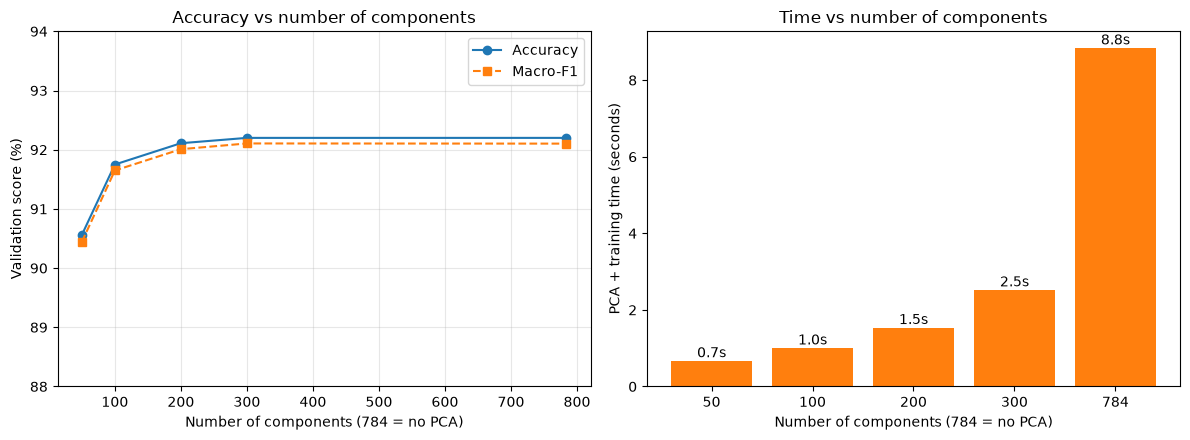

In [10]:
r = results_lr.sort_values("Components")
total_time = r["PCA time (s)"] + r["Train time (s)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(r["Components"], r["Accuracy (%)"], "o-", label="Accuracy")
axes[0].plot(r["Components"], r["Macro-F1 (%)"], "s--", label="Macro-F1")
axes[0].set_xlabel("Number of components (784 = no PCA)")
axes[0].set_ylabel("Validation score (%)")
axes[0].set_title("Accuracy vs number of components")
axes[0].set_ylim(88, 94)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(r["Components"].astype(str), total_time, color="tab:orange")
axes[1].set_xlabel("Number of components (784 = no PCA)")
axes[1].set_ylabel("PCA + training time (seconds)")
axes[1].set_title("Time vs number of components")
for i, t in enumerate(total_time):
    axes[1].text(i, t + 0.1, f"{t:.1f}s", ha="center")

plt.tight_layout()
plt.savefig("lr_accuracy_time.png", dpi=150, bbox_inches="tight")
plt.show()

## Second classifier: Random Forest

To check if the PCA results depend on the model, I repeated the same experiment with a Random Forest (100 decision trees). Random Forest works in a very different way from Logistic Regression: it makes decisions by splitting on one feature at a time instead of combining all features with weights. I used the same PCA settings and the same train and validation sets.

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf_rows = []
for k in [784, 300, 200, 100, 50]:
    start = time.time()
    if k == 784:
        Xtr, Xva = X_train, X_val
    else:
        pca = PCA(n_components=k, random_state=SEED).fit(X_train)
        Xtr, Xva = pca.transform(X_train), pca.transform(X_val)
    pca_time = time.time() - start if k != 784 else 0.0

    start = time.time()
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
    t_train = time.time() - start

    start = time.time()
    pred = rf.predict(Xva)
    t_pred = time.time() - start

    rf_rows.append({
        "Components": k,
        "Accuracy (%)": accuracy_score(y_val, pred) * 100,
        "Macro-F1 (%)": f1_score(y_val, pred, average="macro") * 100,
        "PCA time (s)": pca_time,
        "Train time (s)": t_train,
        "Predict time (s)": t_pred,
    })
    print(f"{k} components done ✅")

results_rf = pd.DataFrame(rf_rows).round(3)
results_rf.to_csv("results_rf.csv", index=False)
results_rf

784 components done ✅
300 components done ✅
200 components done ✅
100 components done ✅
50 components done ✅


,Components,Accuracy (%),Macro-F1 (%),PCA time (s),Train time (s),Predict time (s)
0,784,96.70,96.688,0.000,2.824,0.043
1,300,93.41,93.348,0.248,10.974,0.039
2,200,94.10,94.053,0.203,9.171,0.035
3,100,94.77,94.726,0.172,6.492,0.038
4,50,95.16,95.124,0.157,4.640,0.026


**Finding:** For Random Forest, PCA did not help.
- On all 784 pixels, Random Forest got the best result of the whole project: 96.70% accuracy in only 2.9 seconds.
- With PCA, accuracy dropped to between 93.41% and 95.16%, and training became slower (up to 10.2 seconds with 300 components).
- Strangely, fewer components gave better accuracy for Random Forest (95.16% with 50 vs 93.41% with 300).

**Why I think this happens:**
1. A decision tree splits on one feature at a time. Raw pixels are easy to split on ("is this pixel dark or bright?"). Every PCA component is a mix of all 784 pixels, so a single split on it means less.
2. Most raw pixels are exactly 0, which makes trees quick to build. PCA features are different decimal values everywhere, so the trees take longer.
3. The extra components are mostly noise. Random Forest picks features at random for each split, so having fewer noisy components helps it.

So PCA is not always a good idea. It helped Logistic Regression a lot, but for Random Forest it was better to keep the original pixels.

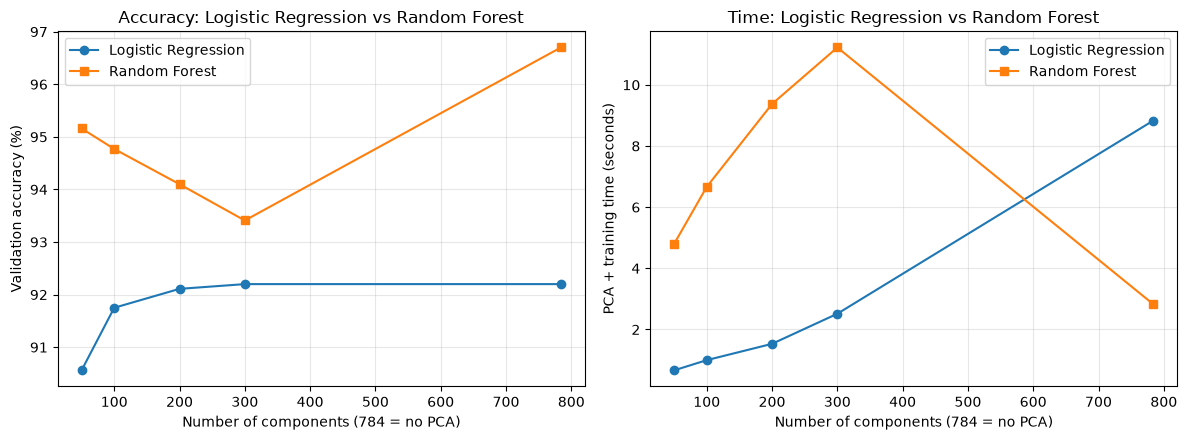

In [12]:
lr = results_lr.sort_values("Components")
rf = results_rf.sort_values("Components")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(lr["Components"], lr["Accuracy (%)"], "o-", label="Logistic Regression")
axes[0].plot(rf["Components"], rf["Accuracy (%)"], "s-", label="Random Forest")
axes[0].set_xlabel("Number of components (784 = no PCA)")
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].set_title("Accuracy: Logistic Regression vs Random Forest")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(lr["Components"], lr["PCA time (s)"] + lr["Train time (s)"], "o-", label="Logistic Regression")
axes[1].plot(rf["Components"], rf["PCA time (s)"] + rf["Train time (s)"], "s-", label="Random Forest")
axes[1].set_xlabel("Number of components (784 = no PCA)")
axes[1].set_ylabel("PCA + training time (seconds)")
axes[1].set_title("Time: Logistic Regression vs Random Forest")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig("lr_vs_rf.png", dpi=150, bbox_inches="tight")
plt.show()

## Final evaluation on the test set

Based on the validation results, I picked three models to test:
1. **Logistic Regression on 784 features** (the baseline)
2. **Logistic Regression with PCA (100 components)**, because it was the best trade-off: almost the same accuracy and about 11 times faster training
3. **Random Forest on 784 features**, because it had the highest accuracy

Since all settings were now fixed, I retrained these models on the full 60,000 training images (train + validation). PCA was also fitted again on these 60,000 images only. The test set was used only once, here, for the final numbers.

In [13]:
final_rows = []
final_preds = {}

def evaluate_final(name, model, Xtr, Xte, pca_time=0.0):
    start = time.time()
    model.fit(Xtr, y_train_full)
    t_train = time.time() - start
    start = time.time()
    pred = model.predict(Xte)
    t_pred = time.time() - start
    final_preds[name] = pred
    final_rows.append({
        "Model": name,
        "Features": Xtr.shape[1],
        "Test accuracy (%)": accuracy_score(y_test, pred) * 100,
        "Test macro-F1 (%)": f1_score(y_test, pred, average="macro") * 100,
        "PCA + train time (s)": pca_time + t_train,
        "Predict time (s)": t_pred,
    })
    print(f"{name} done ✅")

evaluate_final("LR (784 features)",
               LogisticRegression(max_iter=1000, random_state=SEED),
               X_train_full, X_test)

start = time.time()
pca100 = PCA(n_components=100, random_state=SEED).fit(X_train_full)
Xtr100, Xte100 = pca100.transform(X_train_full), pca100.transform(X_test)
pca100_time = time.time() - start
evaluate_final("LR + PCA (100)",
               LogisticRegression(max_iter=1000, random_state=SEED),
               Xtr100, Xte100, pca100_time)

evaluate_final("RF (784 features)",
               RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
               X_train_full, X_test)

final_results = pd.DataFrame(final_rows).round(3)
final_results.to_csv("final_test_results.csv", index=False)
final_results

LR (784 features) done ✅
LR + PCA (100) done ✅
RF (784 features) done ✅


,Model,Features,Test accuracy (%),Test macro-F1 (%),PCA + train time (s),Predict time (s)
0,LR (784 features),784,92.58,92.472,13.068,0.008
1,LR + PCA (100),100,92.18,92.062,1.204,0.001
2,RF (784 features),784,96.92,96.892,4.038,0.040


**Finding (test set):** The test results were very close to the validation results, so the models did not overfit.
- **LR with PCA (100 components)** got 92.18% test accuracy, only 0.40 points less than LR on all 784 features (92.58%). But PCA + training took 1.2 seconds instead of 12.4 seconds, about 10.5 times faster, using 87% fewer features.
- **Random Forest on 784 features** was the most accurate model: 96.92% test accuracy and 96.89% macro-F1, in 3.8 seconds.

## Which digits get confused?

A confusion matrix shows, for every true digit, what the model predicted. The diagonal is correct predictions; everything else is a mistake. I compared the two Logistic Regression models to see if PCA changes which mistakes are made.

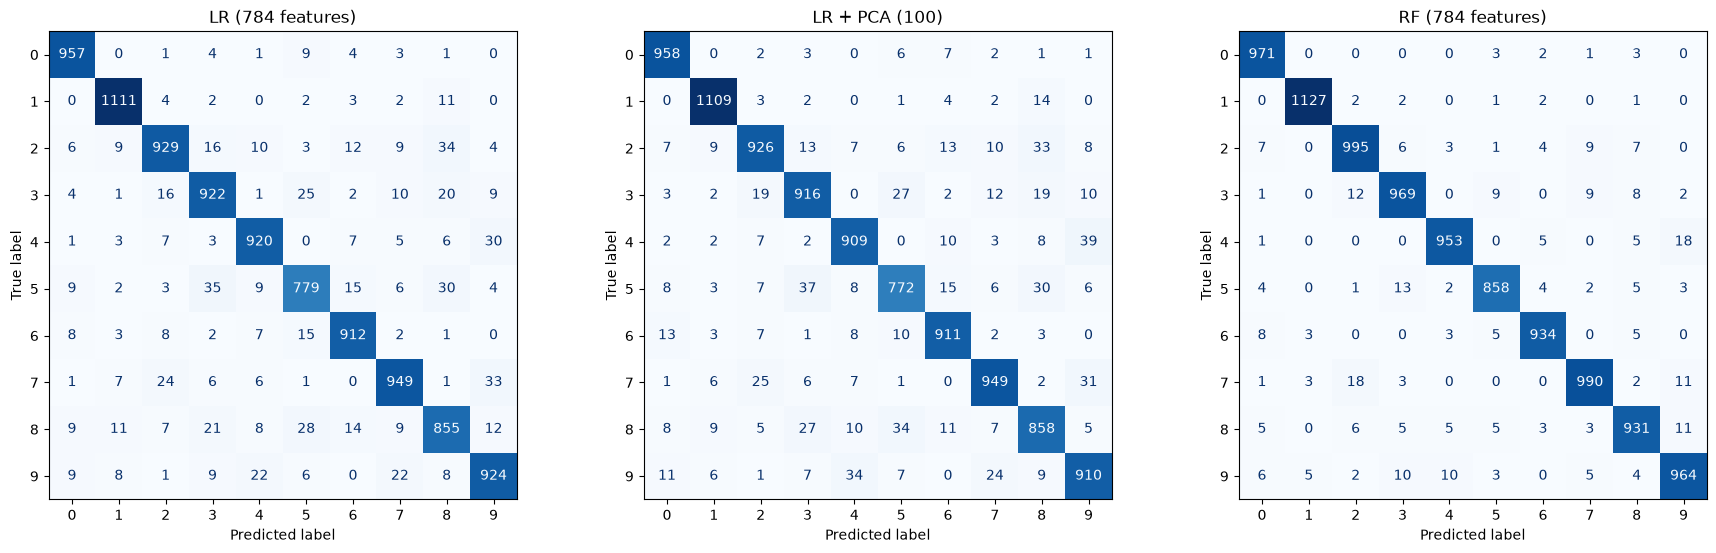

LR (784 features): most common mistake = true 5 predicted as 3 (35 times)
LR + PCA (100): most common mistake = true 4 predicted as 9 (39 times)
RF (784 features): most common mistake = true 4 predicted as 9 (18 times)


In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, final_preds):
    ConfusionMatrixDisplay.from_predictions(
        y_test, final_preds[name], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

for name, pred in final_preds.items():
    cm = confusion_matrix(y_test, pred)
    np.fill_diagonal(cm, 0)
    true_d, pred_d = np.unravel_index(cm.argmax(), cm.shape)
    print(f"{name}: most common mistake = true {true_d} predicted as {pred_d} ({cm.max()} times)")

**Finding:** For all three models, most mistakes were between digits that look alike. Logistic Regression found digit 5 the hardest: only 779 of the 892 test 5s were correct (87.3%), and 5 was most often confused with 3 (35 times) and 8 (30 times). With PCA, the most common mistake became 4 predicted as 9 (39 times). Random Forest made far fewer mistakes overall, and its most common mistake (4 as 9) happened only 18 times. PCA did not create new kinds of mistakes; it made the same ones slightly more often.

## Conclusion

**RQ1: How many components are needed?** Very few. 87 of the 784 components keep 90% of the variance, and 154 keep 95%. This is because many pixels, mostly on the border, never or barely change (65 pixels are always 0).

**RQ2: How do accuracy and F1 change?** For Logistic Regression, hardly at all until the number of components gets very small. Accuracy stayed at 92.20% with 300 components and only fell to 91.75% with 100 on the validation set. Even 50 components gave 90.56%. Macro-F1 followed accuracy closely every time.

**RQ3: How much time does PCA save?** For Logistic Regression, a lot. On the test set, PCA with 100 components cut the time from 12.4 to 1.2 seconds (about 10.5 times faster) for a loss of only 0.40 points of accuracy (92.58% to 92.18%). For Random Forest, PCA made things worse: lower accuracy and slower training. The best model overall was Random Forest on the original 784 pixels (96.92% test accuracy).

**Main lesson:** PCA is very useful when a model is slow on many features, like Logistic Regression, but it is not always helpful. Whether to use it depends on the model.

## Limitations
- I used only one random seed, so I did not measure how much the results vary between runs.
- I did not tune the hyperparameters (for example the regularisation strength of Logistic Regression or the depth of the trees).
- Timings were measured once on my laptop (Apple M3), so they can change a bit between runs and machines.
- MNIST is a clean and simple dataset. On harder data, PCA might lose more useful information.
- I only tried PCA. Other methods for reducing features (like feature selection) were not compared.

## References
1. K. Pearson, "On lines and planes of closest fit to systems of points in space," *Philosophical Magazine*, 1901.
2. H. Hotelling, "Analysis of a complex of statistical variables into principal components," *Journal of Educational Psychology*, 1933.
3. Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, "Gradient-based learning applied to document recognition," *Proceedings of the IEEE*, 1998.
4. F. Pedregosa et al., "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, 2011.
5. MNIST on OpenML: openml.org/d/554